# Telco Customer Churn: tidymodels + XGBoost (R)

**Competition:** [Playground Series S6E3, Predict Customer Churn](https://www.kaggle.com/competitions/playground-series-s6e3). Metric: ROC-AUC.

This is the R counterpart of my [Python GBDT ensemble notebook](https://www.kaggle.com/code/felipeterrazas/s6e3-churn-gbdt-ensemble-python). Same features, built the tidymodels way:

1. Load the data and look at the main churn drivers
2. Add three engineered features
3. Build a recipe and an XGBoost spec
4. Tune hyperparameters on a 100k-row sample (space-filling grid, 3-fold CV)
5. Check the tuned model with 5-fold CV on the full training set
6. Fit on everything and write the submission

Kaggle no longer runs R notebooks, so this one is run locally and published on GitHub at [github.com/FelipeRamiresTerrazas/kaggle](https://github.com/FelipeRamiresTerrazas/kaggle). It still runs on Kaggle's data paths unchanged if R support comes back.

In [1]:
suppressPackageStartupMessages(suppressWarnings({
  library(tidyverse)
  library(tidymodels)
}))
tidymodels_prefer()
options(cli.num_colors = 1, crayon.enabled = FALSE)  # plain text output on GitHub
set.seed(42)

n_cores <- max(1L, parallel::detectCores())
cat("cores:", n_cores,
    "| xgboost", as.character(packageVersion("xgboost")),
    "| parsnip", as.character(packageVersion("parsnip")), "\n")

# The same notebook runs locally and on Kaggle.
on_kaggle <- dir.exists("/kaggle/input")
if (on_kaggle) {
  data_dir <- dirname(list.files("/kaggle/input", pattern = "^train\\.csv$",
                                 recursive = TRUE, full.names = TRUE)[1])
  out_dir  <- "/kaggle/working"
} else {
  data_dir <- "../data"
  out_dir  <- "../submissions"
  dir.create(out_dir, showWarnings = FALSE)
}
data_dir

cores: 12 | xgboost 3.2.1.1 | parsnip 1.6.1 


[1] "../data"

## 1. Data

In [2]:
train <- read_csv(file.path(data_dir, "train.csv"), show_col_types = FALSE)
test  <- read_csv(file.path(data_dir, "test.csv"),  show_col_types = FALSE)

cat(sprintf("train: %s rows x %d cols | test: %s rows\n",
            format(nrow(train), big.mark = ","), ncol(train), format(nrow(test), big.mark = ",")))
train |> count(Churn) |> mutate(share = round(n / sum(n), 3))

train: 594,194 rows x 21 cols | test: 254,655 rows


Churn,n,share
<chr>,<int>,<dbl>
No,460377,0.775
Yes,133817,0.225


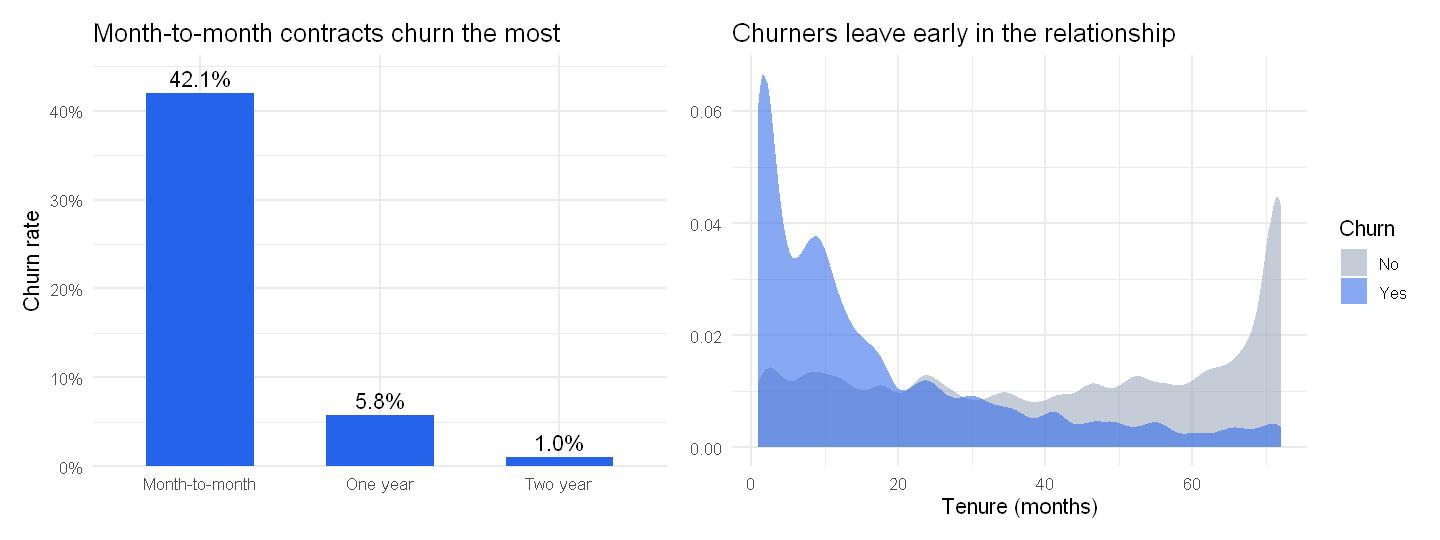

In [3]:
options(repr.plot.width = 12, repr.plot.height = 4.5)
theme_set(theme_minimal(base_size = 13))

churn_rate <- function(df, var) {
  df |>
    group_by({{ var }}) |>
    summarise(rate = mean(Churn == "Yes"), n = n(), .groups = "drop")
}

p1 <- churn_rate(train, Contract) |>
  ggplot(aes(reorder(Contract, -rate), rate)) +
  geom_col(fill = "#2563eb", width = 0.6) +
  geom_text(aes(label = scales::percent(rate, 0.1)), vjust = -0.4) +
  scale_y_continuous(labels = scales::percent, expand = expansion(mult = c(0, 0.1))) +
  labs(x = NULL, y = "Churn rate", title = "Month-to-month contracts churn the most")

p2 <- ggplot(train, aes(tenure, fill = Churn)) +
  geom_density(alpha = 0.55, colour = NA) +
  scale_fill_manual(values = c(No = "#94a3b8", Yes = "#2563eb")) +
  labs(x = "Tenure (months)", y = NULL, title = "Churners leave early in the relationship")

if (requireNamespace("patchwork", quietly = TRUE)) {
  print(patchwork::wrap_plots(p1, p2))
} else {
  print(p1); print(p2)
}

## 2. Features

Three engineered features, the same ones used in the Python notebook:

- `avg_charge`: total charges per month of tenure
- `charge_gap`: how far total charges are from `tenure x MonthlyCharges` (picks up price changes)
- `n_services`: number of add-on services the customer has

In [4]:
services <- c("PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
              "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies")

add_features <- function(df) {
  df |>
    mutate(
      SeniorCitizen = factor(SeniorCitizen, levels = c(0, 1), labels = c("No", "Yes")),
      avg_charge    = TotalCharges / pmax(tenure, 1),
      charge_gap    = TotalCharges - tenure * MonthlyCharges,
      n_services    = rowSums(across(all_of(services), ~ .x == "Yes")),
      across(where(is.character), as.factor)
    )
}

train_fe <- train |> add_features() |> mutate(Churn = factor(Churn, levels = c("Yes", "No")))
test_fe  <- test  |> add_features()
glimpse(train_fe)

Rows: 594,194
Columns: 24
$ id               <dbl> 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15,…
$ gender           <fct> Male, Male, Male, Female, Female, Male, Female, Male,…
$ SeniorCitizen    <fct> No, No, No, No, No, No, No, No, Yes, No, No, No, Yes,…
$ Partner          <fct> Yes, Yes, Yes, No, No, Yes, Yes, Yes, No, No, No, Yes…
$ Dependents       <fct> Yes, Yes, No, No, No, Yes, Yes, No, No, No, No, Yes, …
$ tenure           <dbl> 29, 58, 58, 1, 1, 1, 24, 72, 1, 55, 13, 67, 1, 33, 63…
$ PhoneService     <fct> Yes, Yes, Yes, Yes, Yes, Yes, Yes, Yes, Yes, Yes, Yes…
$ MultipleLines    <fct> No, No, Yes, No, No, No, No, Yes, Yes, No, No, Yes, N…
$ InternetService  <fct> DSL, DSL, Fiber optic, Fiber optic, Fiber optic, No, …
$ OnlineSecurity   <fct> Yes, Yes, No, No, No, No internet service, No interne…
$ OnlineBackup     <fct> No, Yes, Yes, No, No, No internet service, No interne…
$ DeviceProtection <fct> Yes, No, No, No, No, No internet service, No internet…
$ TechSupport 

## 3. Recipe and model

Trees don't need scaling, so the recipe just one-hot encodes the categoricals. `Yes` is the first factor level, so yardstick treats it as the event.

In [5]:
churn_rec <- recipe(Churn ~ ., data = train_fe) |>
  update_role(id, new_role = "id") |>
  step_dummy(all_nominal_predictors(), one_hot = TRUE)

n_predictors <- ncol(bake(prep(churn_rec, training = head(train_fe, 1000)), new_data = NULL)) - 2
cat("predictors after encoding:", n_predictors, "\n")

xgb_spec <- boost_tree(
  trees          = 600,
  tree_depth     = tune(),
  min_n          = tune(),
  loss_reduction = tune(),
  sample_size    = tune(),
  mtry           = tune(),
  learn_rate     = tune()
) |>
  set_engine("xgboost", nthread = n_cores) |>
  set_mode("classification")

churn_wf <- workflow() |> add_recipe(churn_rec) |> add_model(xgb_spec)

predictors after encoding: 49 


## 4. Tuning on a sample

Tuning on all 594k rows would take hours on a laptop CPU. A stratified 100k-row sample with 3-fold CV is enough to rank the candidates, and the winner is then checked on the full data in step 5.

In [6]:
tune_sample <- training(initial_split(train_fe, prop = 100000 / nrow(train_fe), strata = Churn))
tune_folds  <- vfold_cv(tune_sample, v = 3, strata = Churn)

params <- extract_parameter_set_dials(churn_wf) |>
  update(
    tree_depth     = tree_depth(c(3L, 8L)),
    min_n          = min_n(c(20L, 300L)),
    loss_reduction = loss_reduction(c(-3, 0.5)),
    sample_size    = sample_prop(c(0.6, 1)),
    mtry           = mtry(c(10L, n_predictors)),
    learn_rate     = learn_rate(c(-1.7, -0.8))
  )

grid_fn <- if (exists("grid_space_filling", envir = asNamespace("dials"))) {
  dials::grid_space_filling
} else {
  dials::grid_latin_hypercube
}
xgb_grid <- grid_fn(params, size = 12)

t0 <- Sys.time()
tune_res <- tune_grid(
  churn_wf,
  resamples = tune_folds,
  grid      = xgb_grid,
  metrics   = metric_set(roc_auc),
  control   = control_grid(verbose = FALSE)
)
cat("tuning took", round(difftime(Sys.time(), t0, units = "mins"), 1), "min\n")

show_best(tune_res, metric = "roc_auc", n = 5)

tuning took 10.2 min


mtry,min_n,tree_depth,learn_rate,loss_reduction,sample_size,.metric,.estimator,mean,n,std_err,.config
<int>,<int>,<int>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
41,45,3,0.03511192,0.081113083,0.8181818,roc_auc,binary,0.9137057,3,0.0006210234,pre0_mod10_post0
24,96,6,0.02908281,0.002080568,0.6000000,roc_auc,binary,0.9134303,3,0.0005978029,pre0_mod05_post0
45,300,4,0.06178870,0.018738174,0.6727273,roc_auc,binary,0.9133749,3,0.0005793633,pre0_mod11_post0
10,198,3,0.04239091,0.730527154,0.7090909,roc_auc,binary,0.9132798,3,0.0005489089,pre0_mod01_post0
27,249,5,0.01995262,0.009006280,0.9636364,roc_auc,binary,0.9132729,3,0.0006166895,pre0_mod06_post0


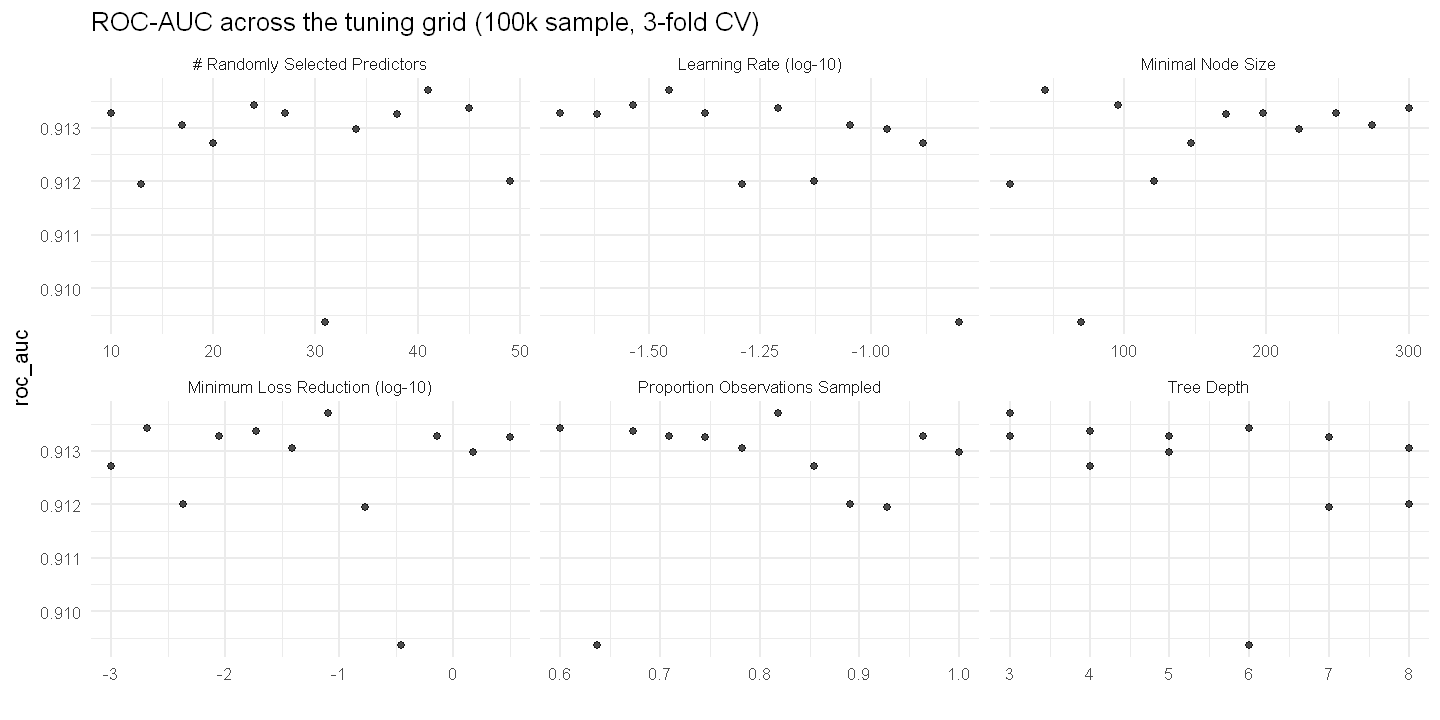

In [7]:
options(repr.plot.width = 12, repr.plot.height = 6)
autoplot(tune_res) + labs(title = "ROC-AUC across the tuning grid (100k sample, 3-fold CV)")

## 5. Validate on the full training set

5-fold stratified CV with the tuned parameters on all 594k rows. This is the number to compare with the Python ensemble.

In [8]:
best_params <- select_best(tune_res, metric = "roc_auc")
final_wf    <- finalize_workflow(churn_wf, best_params)

t0 <- Sys.time()
cv_res <- fit_resamples(
  final_wf,
  resamples = vfold_cv(train_fe, v = 5, strata = Churn),
  metrics   = metric_set(roc_auc),
  control   = control_resamples(save_pred = TRUE)
)
cat("5-fold CV took", round(difftime(Sys.time(), t0, units = "mins"), 1), "min\n")

collect_metrics(cv_res, summarize = FALSE) |> select(id, .estimate)
collect_metrics(cv_res)

5-fold CV took 6.3 min


id,.estimate
<chr>,<dbl>
Fold1,0.9141992
Fold2,0.9162585
Fold3,0.9158528
Fold4,0.9150024
Fold5,0.9145465


.metric,.estimator,mean,n,std_err,.config
<chr>,<chr>,<dbl>,<int>,<dbl>,<chr>
roc_auc,binary,0.9151719,5,0.0003879573,pre0_mod0_post0


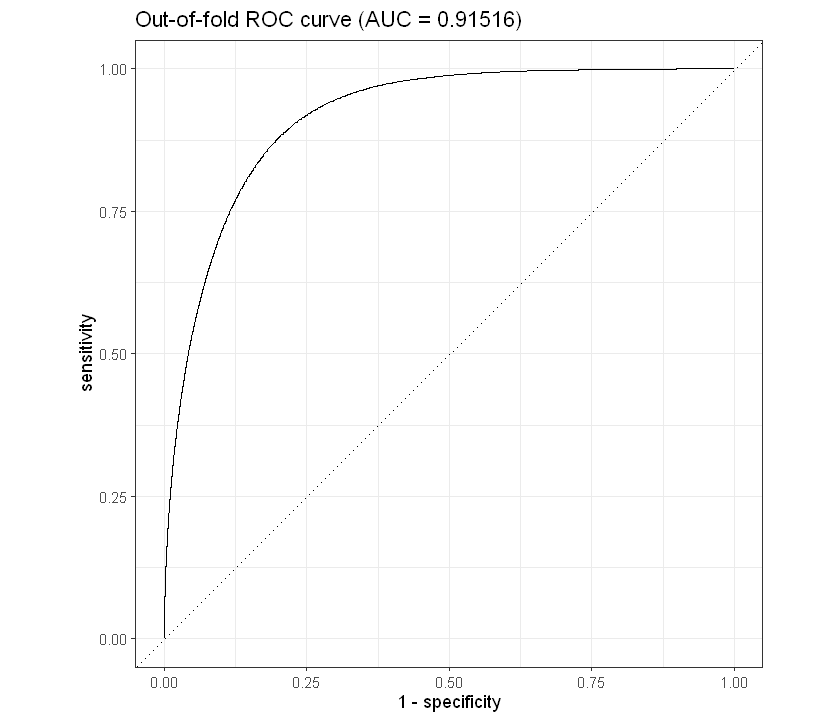

In [9]:
options(repr.plot.width = 7, repr.plot.height = 6)
oof_auc <- collect_predictions(cv_res) |> roc_auc(Churn, .pred_Yes) |> pull(.estimate)
collect_predictions(cv_res) |>
  roc_curve(Churn, .pred_Yes) |>
  autoplot() +
  labs(title = sprintf("Out-of-fold ROC curve (AUC = %.5f)", oof_auc))

## 6. Final fit and submission

In [10]:
t0 <- Sys.time()
final_fit <- fit(final_wf, data = train_fe)
cat("final fit took", round(difftime(Sys.time(), t0, units = "mins"), 1), "min\n")

final fit took 0.9 min


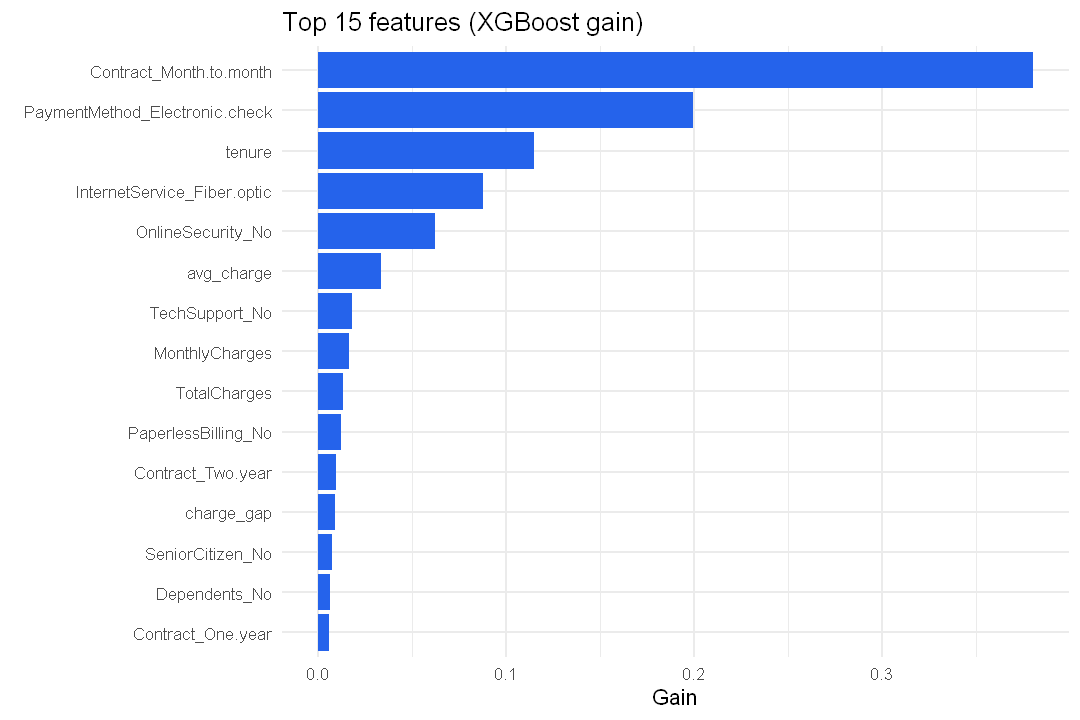

In [11]:
# Top features by gain
importance <- tryCatch(
  xgboost::xgb.importance(model = extract_fit_engine(final_fit)),
  error = function(e) NULL
)
if (!is.null(importance)) {
  options(repr.plot.width = 9, repr.plot.height = 6)
  importance |>
    as_tibble() |>
    slice_max(Gain, n = 15) |>
    ggplot(aes(Gain, reorder(Feature, Gain))) +
    geom_col(fill = "#2563eb") +
    labs(x = "Gain", y = NULL, title = "Top 15 features (XGBoost gain)")
}

In [12]:
test_pred  <- predict(final_fit, new_data = test_fe, type = "prob")
submission <- tibble(id = test_fe$id, Churn = test_pred$.pred_Yes)

stopifnot(nrow(submission) == nrow(test), !anyNA(submission$Churn),
          all(between(submission$Churn, 0, 1)))

write_csv(submission, file.path(out_dir, "submission_r.csv"))
summary(submission$Churn)
head(submission)

     Min.   1st Qu.    Median      Mean   3rd Qu.      Max. 
0.0006919 0.0072532 0.0654811 0.2180976 0.3922492 0.9805088 

id,Churn
<dbl>,<dbl>
594194,0.059202667
594195,0.001478187
594196,0.085269004
594197,0.002618407
594198,0.519114852
594199,0.167407572
